<a href="https://colab.research.google.com/github/Peter0176/COU07506-labs/blob/main/COU07506_Week02_240242462943.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 COU 07506 Digital Signal Processing Week 02: Lab 1A Sampling, Aliasing and Quantization

Name:PETER JACKSON LUCASI
 Registration No.:240242462943
Class: BEng24COE
 Group: 6 Date: 25/11/2026


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display
plt.rcParams["figure.figsize"] = (9, 3.5)

Task 2.1 Aliasing of a sinusoid

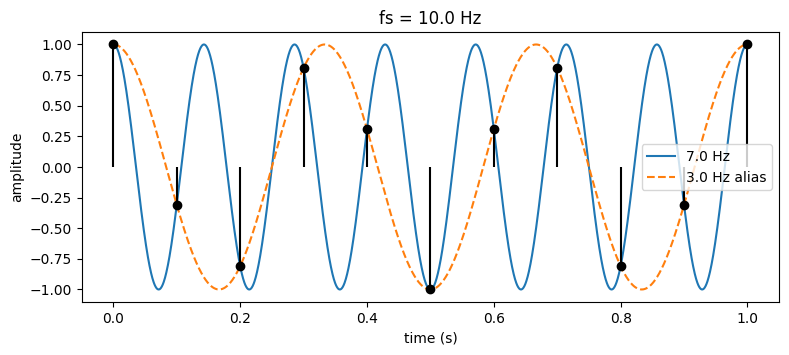

In [2]:
f0, fs = 7.0, 10.0
t = np.linspace(0, 1, 2000)
n = np.arange(0, int(fs) + 1)
tn = n / fs
f_alias = abs(f0 - fs*round(f0/fs))
plt.plot(t, np.cos(2*np.pi*f0*t), label=f"{f0} Hz")
plt.plot(t, np.cos(2*np.pi*f_alias*t), "--", label=f"{f_alias} Hz alias")
plt.stem(tn, np.cos(2*np.pi*f0*tn), linefmt="k-", markerfmt="ko", basefmt=" ")
plt.xlabel("time (s)"); plt.ylabel("amplitude")
plt.title(f"fs = {fs} Hz"); plt.legend(); plt.show()

Task 2.2 Hear aliasing

In [11]:
fname = "voice_Ptt_2026-11-24_at_23_02_00.wav"
import os
import warnings
warnings.filterwarnings("ignore", category=wavfile.WavFileWarning)
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)
    x = x / np.max(np.abs(x))
else:
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5*signal.chirp(t, 200, 3, 15000)

for k in [2, 4, 8]:
    naive  = x[::k]
    proper = signal.decimate(x, k, ftype="fir")
    print(k, "new fs =", fs // k, "Hz")
    display(Audio(naive,  rate=fs//k))
    display(Audio(proper, rate=fs//k))

2 new fs = 24000 Hz


4 new fs = 12000 Hz


8 new fs = 6000 Hz


Task 2.3 Uniform quantizer

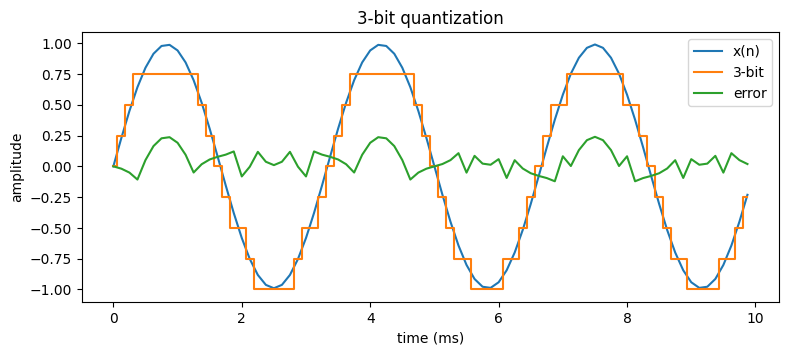

In [12]:
def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits
    q = np.round(x/delta)*delta
    return np.clip(q, -full_scale, full_scale - delta)

fs_s = 8000
t_s = np.arange(0, 0.01, 1/fs_s)
xs = 0.99*np.sin(2*np.pi*300*t_s)
xq = quantize(xs, 3)
plt.plot(t_s*1e3, xs, label="x(n)")
plt.step(t_s*1e3, xq, where="mid", label="3-bit")
plt.plot(t_s*1e3, xs - xq, label="error")
plt.xlabel("time (ms)"); plt.ylabel("amplitude")
plt.title("3-bit quantization"); plt.legend(); plt.show()

Task 2.4 –To Verify the 6 dB per bit rule

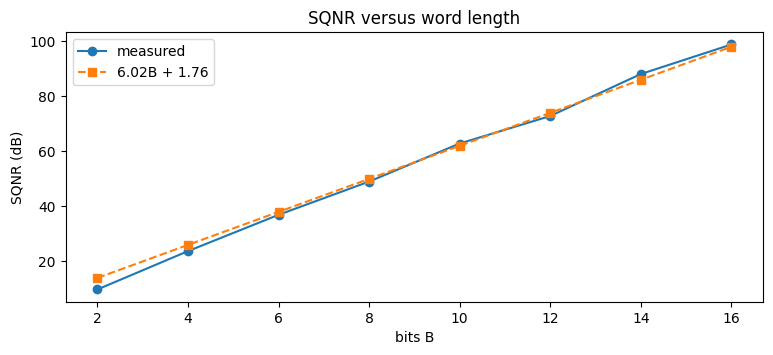

In [13]:
bits = np.arange(2, 17, 2)
meas = [10*np.log10(np.sum(xs**2)/np.sum((xs - quantize(xs, B))**2)) for B in bits]
plt.plot(bits, meas, "o-", label="measured")
plt.plot(bits, 6.02*bits + 1.76, "s--", label="6.02B + 1.76")
plt.xlabel("bits B"); plt.ylabel("SQNR (dB)")
plt.title("SQNR versus word length"); plt.legend(); plt.show()

Task 2.5 To quantize the voice

In [14]:
import os

if os.path.exists(fname):
    fs_v, xv = wavfile.read(fname)
    xv = xv.mean(axis=1) if xv.ndim > 1 else xv.astype(float)
    xv = xv / np.max(np.abs(xv))
else:
    print(f"File '{fname}'")
    fs_v = fs
    xv = x

for B in [4, 8, 12]:
    xvq = quantize(xv, B)
    sqnr = 10*np.log10(np.sum(xv**2)/np.sum((xv - xvq)**2))
    print(f"{B} bits: SQNR = {sqnr:.1f} dB")
    display(Audio(xvq, rate=fs_v))

4 bits: SQNR = 12.6 dB


8 bits: SQNR = 33.9 dB


12 bits: SQNR = 57.5 dB


Analysis
1. Why the 7 Hz tone appears at 3 Hz when fs = 10 Hz

Sampling makes the spectrum repeat every fs = 10 Hz. A 7 Hz tone has spectral lines at ±7 Hz, and copies of them appear at ±7 + k·10 Hz. The copy of −7 Hz shifted by +10 Hz lands at +3 Hz, inside the range 0 to fs/2 = 5 Hz that a sampled signal can represent. Nothing exists at 7 Hz in that range, so the only visible line is at 3 Hz.

2. Why the aliasing in the naive version cannot be removed afterwards

After downsampling without a filter, the high-frequency content has folded into the lower band and sits on the same frequencies as genuine content. Its samples are identical to those of a real low-frequency signal, so the information about where it came from is lost. No later filter can separate the two. The anti-aliasing low-pass filter must act before sampling (or before discarding samples), as signal.decimate does.

3. Change in SQNR when one bit is added

About 6 dB (6.02 dB). One extra bit halves the step Δ, so the noise power Δ²/12 falls by a factor of 4, which is 10·log10(4) ≈ 6.02 dB.